In [43]:
import pandas as pd

data = pd.read_csv("./outputs/femur_data.csv", sep=',')
data = data[data["include"]]
data = data.reset_index(drop="True")
data


,subject_id,study_type,side,has_femur,femur_voxels,volume_ml,superior_cut,extent_from_top_mm,metal_voxels,include,excluded_reason
0,s1366,ct polytrauma,left,True,44219,149.239125,False,150.0,0.0,True,NaN
1,s1366,ct polytrauma,right,True,42147,142.246125,False,136.5,0.0,True,NaN
2,s0250,ct neck-thorax-abdomen-pelvis,left,True,59025,199.209375,False,100.5,0.0,True,NaN
3,s0250,ct neck-thorax-abdomen-pelvis,right,True,60168,203.067000,False,100.5,0.0,True,NaN
4,s0058,ct thorax-abdomen-pelvis,left,True,47187,159.256125,False,102.0,0.0,True,NaN
...,...,...,...,...,...,...,...,...,...,...,...
70,s1379,ct angiography thorax-abdomen-pelvis,right,True,64083,216.280125,False,108.0,0.0,True,NaN
71,s0763,ct polytrauma,left,True,53638,181.028250,False,120.0,0.0,True,NaN
72,s0763,ct polytrauma,right,True,52856,178.389000,False,111.0,0.0,True,NaN
73,s0762,ct thorax-abdomen-pelvis,left,True,61171,206.452125,False,130.5,0.0,True,NaN


(333, 336) 0.0 5.4276896


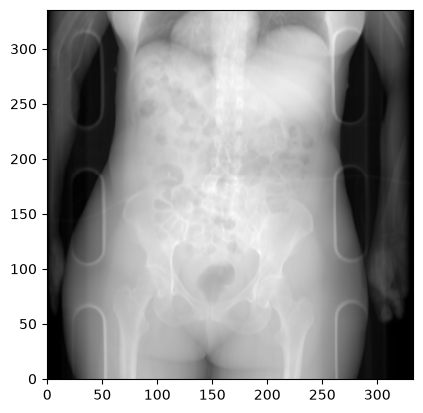

In [57]:
import scipy
import nibabel as nib
import numpy as np
import matplotlib.pyplot 

def loadData(label): # Load a single CT with both femurs
    ct = nib.load(f"dataset/{label}/ct.nii.gz")
    femurLeft = nib.load(f"dataset/{label}/segmentations/femur_left.nii.gz")
    femurRight = nib.load(f"dataset/{label}/segmentations/femur_right.nii.gz")

    return ct, {"left": femurLeft, "right": femurRight}


def plotImage(image):
    intensity = image.get_fdata(dtype=np.float32)

    print("\nmax value: ", intensity.max())
    print("\nmin value: ", intensity.min())
    matplotlib.pyplot.hist(intensity.ravel(), bins=100, log=True)

def clipHU(image, min, max):
    clippedData = np.clip(image.get_fdata(), min, max)
    clippedImage = nib.Nifti1Image(clippedData, image.affine, image.header)

    return clippedImage

def reorient(image):
    return nib.as_closest_canonical(image)

def generateDRR(image):
    hu = image.get_fdata(dtype=np.float32)       # hu values per voxel
    mu = 0.02 * (1 + hu / 1000)                  # attenuation per mm
    spacing = image.header.get_zooms()[1]        # voxel length front to back

    return mu.sum(axis=1) * spacing              # sum along each ray -> 2D image

    
# Load first example
ct, femurs = loadData(data['subject_id'][0])

ct = clipHU(ct, -1000, 3000)
ct = reorient(ct)
femurs["left"] = reorient(femurs["left"])
femurs["right"] = reorient(femurs["right"])

drr = generateDRR(ct)
print(drr.shape, drr.min(), drr.max())
matplotlib.pyplot.imshow(drr.T, cmap="gray", origin="lower")